In [1]:
import pandas as pd
import numpy as np

pd.set_option('display.max_columns', None)

df = pd.read_csv('../data/marketing_campaign_data.csv')
data_dict = pd.read_csv('../data/marketing_data_dictionary.csv')

print("Shape:", df.shape)
df.info()
df.head()

Shape: (56000, 28)
<class 'pandas.DataFrame'>
RangeIndex: 56000 entries, 0 to 55999
Data columns (total 28 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   56000 non-null  int64  
 1   Year_Birth           56000 non-null  int64  
 2   Education            56000 non-null  str    
 3   Marital_Status       56000 non-null  str    
 4   Income               56000 non-null  float64
 5   Kidhome              56000 non-null  int64  
 6   Teenhome             56000 non-null  int64  
 7   Dt_Customer          56000 non-null  str    
 8   Recency              56000 non-null  int64  
 9   MntWines             56000 non-null  int64  
 10  MntFruits            56000 non-null  int64  
 11  MntMeatProducts      56000 non-null  int64  
 12  MntFishProducts      56000 non-null  int64  
 13  MntSweetProducts     56000 non-null  int64  
 14  MntGoldProds         56000 non-null  int64  
 15  NumDealsPurchases    56000 n

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain,Country
0,342199,1985,Graduation,Together,59011.7,1,0,2012-11-17,3,0,2,45,6,0,16,3,2,5,3,4,0,0,0,0,0,0,0,Spain
1,8075450,1975,Master,Single,1730.0,1,1,2013-04-10,96,0,0,19,1,19,0,1,1,0,2,3,0,0,0,0,0,0,0,Spain
2,13664263,1978,Graduation,Married,98584.6,0,0,2014-01-11,99,920,0,339,0,115,138,3,2,1,6,3,0,0,0,0,0,0,0,Australia
3,16164787,1976,Graduation,Married,74031.5,1,0,2014-06-18,47,265,0,130,7,1,75,1,4,0,11,4,0,0,0,0,0,0,0,Spain
4,15815139,1981,Graduation,Divorced,52784.2,1,1,2014-05-20,0,30,3,55,242,0,0,1,3,2,3,6,0,0,0,0,0,0,0,Canada


In [2]:
# Check missing values and duplicates
print("=== Missing Values ===")
print(df.isnull().sum())

print("\n=== Duplicate Rows ===")
print("Full duplicates:", df.duplicated().sum())
print("Duplicate IDs:", df['ID'].duplicated().sum())

print("\n=== Unique Marital Status values ===")
print(df['Marital_Status'].unique())

print("\n=== Unique Education values ===")
print(df['Education'].unique())

print("\n=== Unique Country values ===")
print(df['Country'].unique())

print("\n=== Income Stats ===")
print(df['Income'].describe())

print("\n=== Year_Birth Stats ===")
print(df['Year_Birth'].describe())

=== Missing Values ===
ID                     0
Year_Birth             0
Education              0
Marital_Status         0
Income                 0
Kidhome                0
Teenhome               0
Dt_Customer            0
Recency                0
MntWines               0
MntFruits              0
MntMeatProducts        0
MntFishProducts        0
MntSweetProducts       0
MntGoldProds           0
NumDealsPurchases      0
NumWebPurchases        0
NumCatalogPurchases    0
NumStorePurchases      0
NumWebVisitsMonth      0
AcceptedCmp3           0
AcceptedCmp4           0
AcceptedCmp5           0
AcceptedCmp1           0
AcceptedCmp2           0
Response               0
Complain               0
Country                0
dtype: int64

=== Duplicate Rows ===
Full duplicates: 0
Duplicate IDs: 0

=== Unique Marital Status values ===
<StringArray>
['Together', 'Single', 'Married', 'Divorced', 'YOLO', 'Alone', 'Widow',
 'Absurd']
Length: 8, dtype: str

=== Unique Education values ===
<StringArray>


In [3]:
# ============================================================
# CELL 3 - DATA CLEANING & FEATURE ENGINEERING
# ============================================================

# --- 1. Fix Marital Status ---
# Merge odd categories into standard ones
marital_map = {
    'Together': 'Together',
    'Married': 'Married',
    'Single': 'Single',
    'Divorced': 'Divorced',
    'Widow': 'Widow',
    'YOLO': 'Single',
    'Alone': 'Single',
    'Absurd': 'Single'
}
df['Marital_Status'] = df['Marital_Status'].map(marital_map)
print("Cleaned Marital Status values:", df['Marital_Status'].unique())

# --- 2. Convert Dt_Customer to datetime ---
df['Dt_Customer'] = pd.to_datetime(df['Dt_Customer'])
print("Dt_Customer dtype:", df['Dt_Customer'].dtype)

# --- 3. Derive Customer_Tenure (days since enrollment) ---
reference_date = pd.to_datetime('2024-12-31')
df['Customer_Tenure'] = (reference_date - df['Dt_Customer']).dt.days
print("Customer_Tenure sample:\n", df['Customer_Tenure'].describe())

# --- 4. Derive Age ---
df['Age'] = 2024 - df['Year_Birth']
print("\nAge stats:\n", df['Age'].describe())

# --- 5. Remove unrealistic ages (e.g. age > 90) ---
print("Customers with age > 90:", (df['Age'] > 90).sum())
df = df[df['Age'] <= 90].copy()
print("Shape after removing age outliers:", df.shape)

# --- 6. Remove extreme Income outliers (above 200000) ---
print("Customers with Income > 200000:", (df['Income'] > 200000).sum())
df = df[df['Income'] <= 200000].copy()
print("Shape after removing income outliers:", df.shape)

# --- 7. Derive Total_Spend ---
spend_cols = ['MntWines','MntFruits','MntMeatProducts',
              'MntFishProducts','MntSweetProducts','MntGoldProds']
df['Total_Spend'] = df[spend_cols].sum(axis=1)
print("\nTotal_Spend stats:\n", df['Total_Spend'].describe())

# --- 8. Derive Total_Purchases ---
purchase_cols = ['NumDealsPurchases','NumWebPurchases',
                 'NumCatalogPurchases','NumStorePurchases']
df['Total_Purchases'] = df[purchase_cols].sum(axis=1)

# --- 9. Derive Children ---
df['Children'] = df['Kidhome'] + df['Teenhome']

# --- 10. Final shape ---
print("\nFinal cleaned dataframe shape:", df.shape)
print("New columns added:", ['Age','Customer_Tenure','Total_Spend','Total_Purchases','Children'])
df.head()

Cleaned Marital Status values: <StringArray>
['Together', 'Single', 'Married', 'Divorced', 'Widow']
Length: 5, dtype: str
Dt_Customer dtype: datetime64[us]
Customer_Tenure sample:
 count    56000.000000
mean      4155.687286
std        220.316266
min       3838.000000
25%       3949.000000
50%       4152.000000
75%       4359.000000
max       4537.000000
Name: Customer_Tenure, dtype: float64

Age stats:
 count    56000.000000
mean        52.333304
std         12.211066
min         28.000000
25%         43.000000
50%         51.000000
75%         61.000000
max         88.000000
Name: Age, dtype: float64
Customers with age > 90: 0
Shape after removing age outliers: (56000, 30)
Customers with Income > 200000: 6
Shape after removing income outliers: (55994, 30)

Total_Spend stats:
 count    55994.000000
mean       640.270475
std        622.617892
min          0.000000
25%        103.000000
50%        441.000000
75%       1020.000000
max       3431.000000
Name: Total_Spend, dtype: float64



,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain,Country,Customer_Tenure,Age,Total_Spend,Total_Purchases,Children
0,342199,1985,Graduation,Together,59011.7,1,0,2012-11-17,3,0,2,45,6,0,16,3,2,5,3,4,0,0,0,0,0,0,0,Spain,4427,39,69,13,1
1,8075450,1975,Master,Single,1730.0,1,1,2013-04-10,96,0,0,19,1,19,0,1,1,0,2,3,0,0,0,0,0,0,0,Spain,4283,49,39,4,2
2,13664263,1978,Graduation,Married,98584.6,0,0,2014-01-11,99,920,0,339,0,115,138,3,2,1,6,3,0,0,0,0,0,0,0,Australia,4007,46,1512,12,0
3,16164787,1976,Graduation,Married,74031.5,1,0,2014-06-18,47,265,0,130,7,1,75,1,4,0,11,4,0,0,0,0,0,0,0,Spain,3849,48,478,16,1
4,15815139,1981,Graduation,Divorced,52784.2,1,1,2014-05-20,0,30,3,55,242,0,0,1,3,2,3,6,0,0,0,0,0,0,0,Canada,3878,43,330,9,2


In [4]:
# ============================================================
# CELL 4 - RULE-BASED SEGMENTATION
# ============================================================

# --- High Spender threshold (90th percentile) ---
spend_90 = df['Total_Spend'].quantile(0.90)
print("90th percentile of Total_Spend:", spend_90)

# --- Apply segments ---
df['Seg_HighIncome']       = (df['Income'] > 75000).astype(int)
df['Seg_YoungCustomer']    = (df['Age'] < 30).astype(int)
df['Seg_CampaignResponder']= (df['Response'] == 1).astype(int)
df['Seg_HighWebEngagement']= (df['NumWebVisitsMonth'] > 5).astype(int)
df['Seg_FamilyCustomer']   = (df['Children'] > 0).astype(int)
df['Seg_HighSpender']      = (df['Total_Spend'] > spend_90).astype(int)

# --- Summary of each segment ---
seg_cols = ['Seg_HighIncome','Seg_YoungCustomer','Seg_CampaignResponder',
            'Seg_HighWebEngagement','Seg_FamilyCustomer','Seg_HighSpender']

print("\n=== Segment Counts ===")
for col in seg_cols:
    count = df[col].sum()
    pct = round(count / len(df) * 100, 2)
    print(f"{col}: {count} customers ({pct}%)")

df[seg_cols].head()

90th percentile of Total_Spend: 1564.0

=== Segment Counts ===
Seg_HighIncome: 19776 customers (35.32%)
Seg_YoungCustomer: 1325 customers (2.37%)
Seg_CampaignResponder: 8264 customers (14.76%)
Seg_HighWebEngagement: 29969 customers (53.52%)
Seg_FamilyCustomer: 38220 customers (68.26%)
Seg_HighSpender: 5597 customers (10.0%)


,Seg_HighIncome,Seg_YoungCustomer,Seg_CampaignResponder,Seg_HighWebEngagement,Seg_FamilyCustomer,Seg_HighSpender
0,0,0,0,0,1,0
1,0,0,0,0,1,0
2,1,0,0,0,0,0
3,0,0,0,0,1,0
4,0,0,0,1,1,0


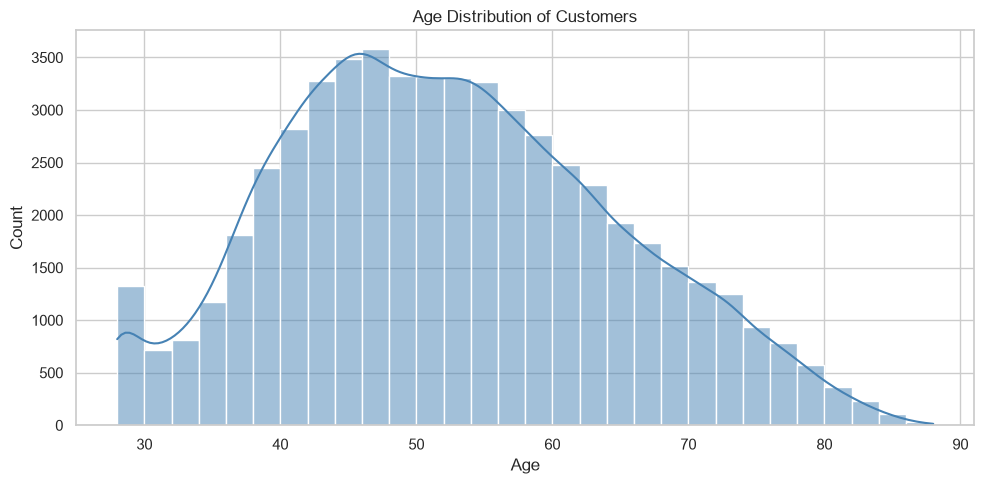

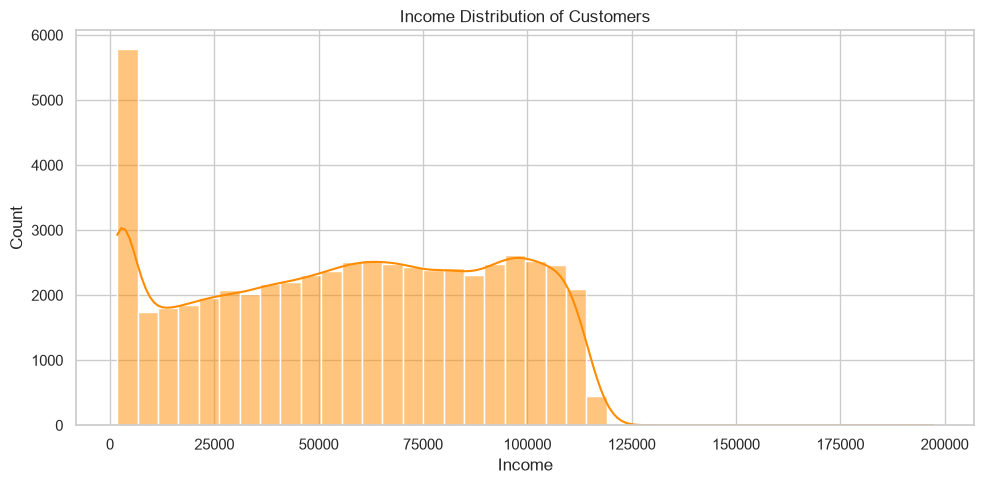

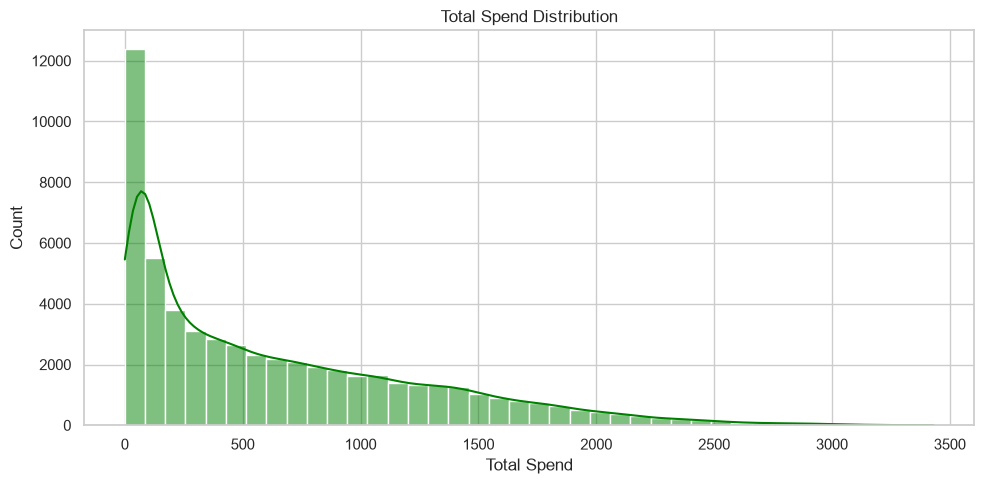

C:\Users\jayar\AppData\Local\Temp\ipykernel_7440\154735056.py:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=response_edu, x='Education', y='Response_Rate', palette='Blues_d')


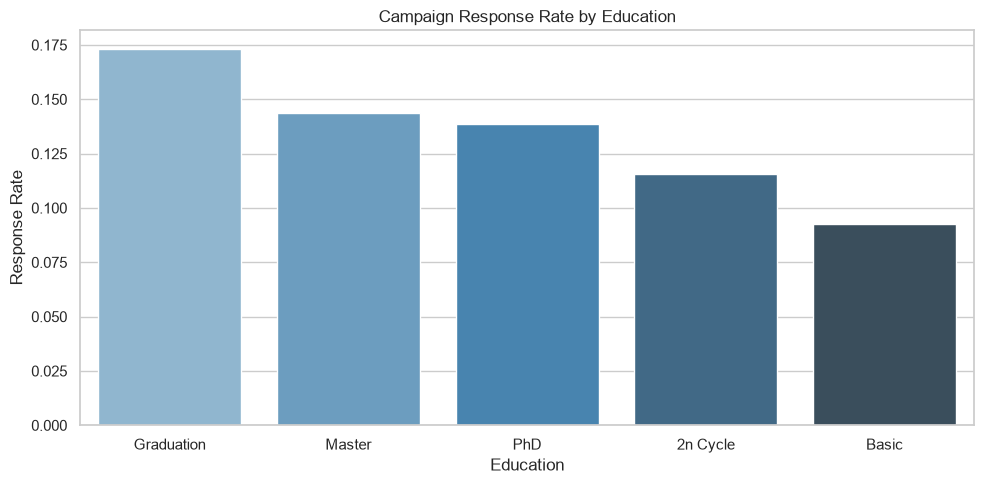

    Education  Response_Rate
2  Graduation       0.173014
3      Master       0.143508
4         PhD       0.138474
0    2n Cycle       0.115488
1       Basic       0.092801


C:\Users\jayar\AppData\Local\Temp\ipykernel_7440\154735056.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=response_marital, x='Marital_Status', y='Response_Rate', palette='Oranges_d')


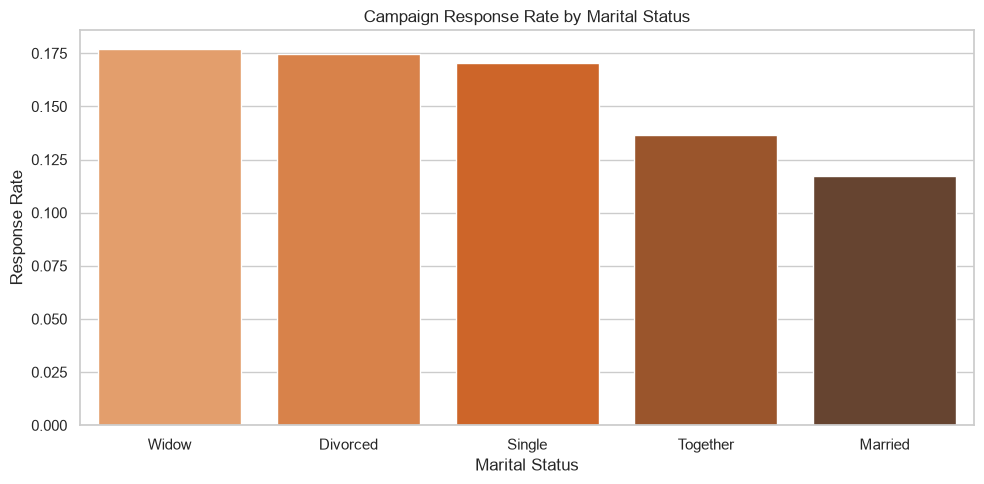

  Marital_Status  Response_Rate
4          Widow       0.176886
0       Divorced       0.174795
2         Single       0.170351
3       Together       0.136546
1        Married       0.117144


C:\Users\jayar\AppData\Local\Temp\ipykernel_7440\154735056.py:88: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=spend_edu, x='Education', y='Total_Spend', palette='Greens_d')


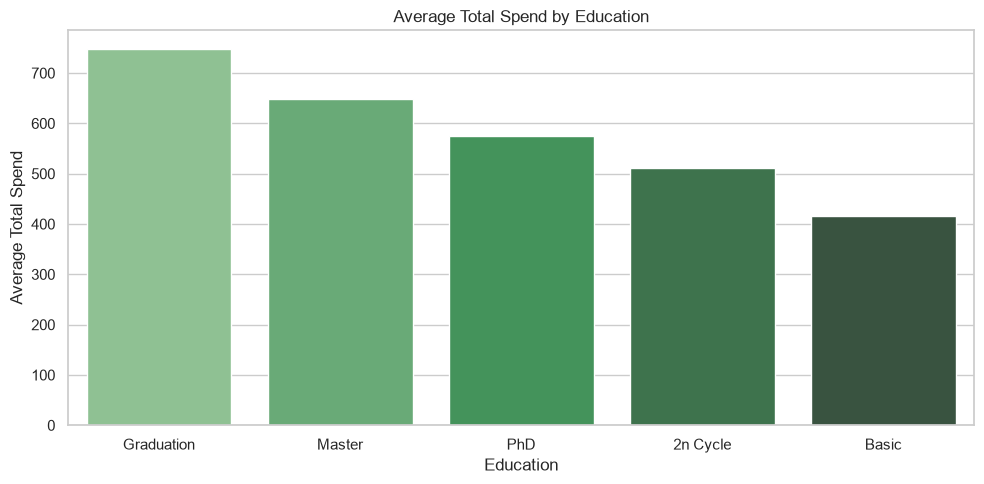

    Education  Total_Spend
2  Graduation   747.251297
3      Master   648.427676
4         PhD   575.700795
0    2n Cycle   511.298190
1       Basic   416.237503


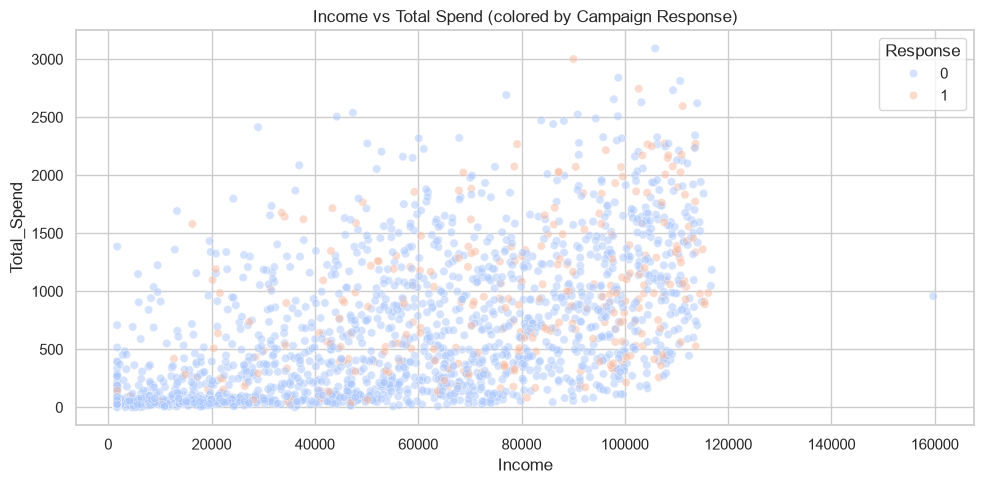

C:\Users\jayar\AppData\Local\Temp\ipykernel_7440\154735056.py:118: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=avg_spend, x='Product', y='Avg_Spend', palette='viridis')


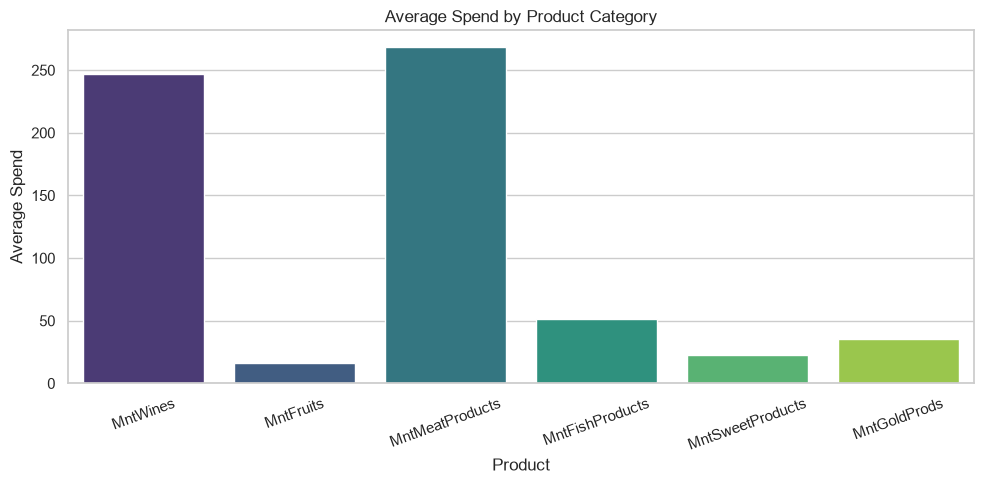

            Product   Avg_Spend
0          MntWines  246.968372
1         MntFruits   16.152248
2   MntMeatProducts  268.254206
3   MntFishProducts   51.095385
4  MntSweetProducts   22.416955
5      MntGoldProds   35.383309


C:\Users\jayar\AppData\Local\Temp\ipykernel_7440\154735056.py:137: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=avg_channel, x='Channel', y='Avg_Purchases', palette='Set2')


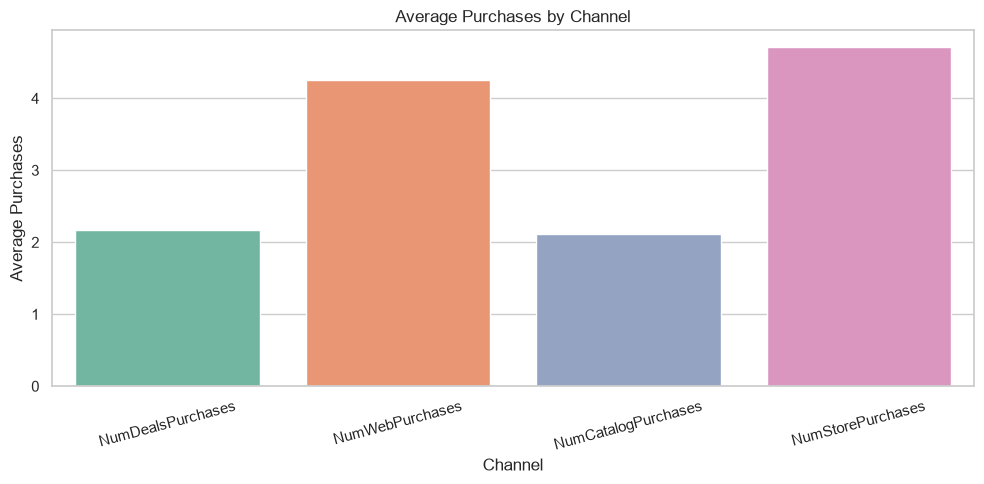

               Channel  Avg_Purchases
0    NumDealsPurchases       2.171893
1      NumWebPurchases       4.248830
2  NumCatalogPurchases       2.110601
3    NumStorePurchases       4.706326


C:\Users\jayar\AppData\Local\Temp\ipykernel_7440\154735056.py:155: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=response_country, x='Country', y='Response_Rate', palette='Purples_d')


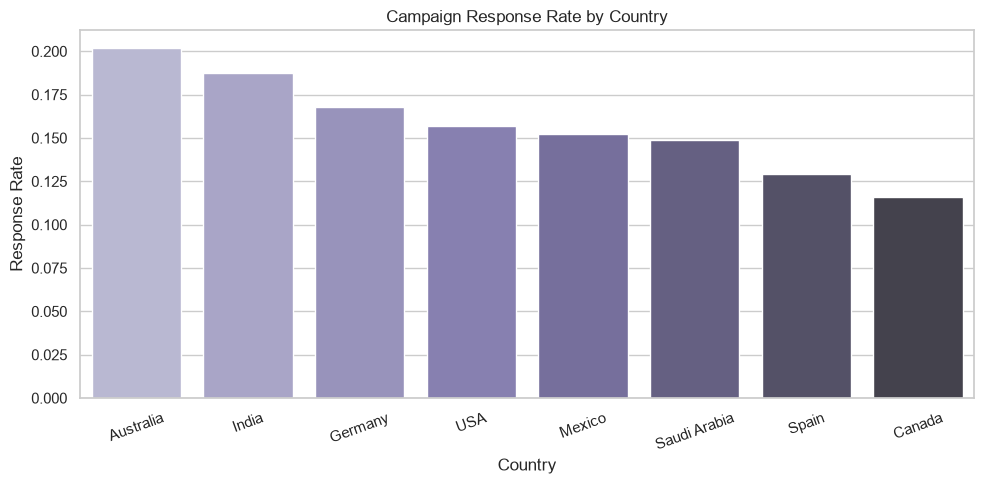

        Country  Response_Rate
0     Australia       0.201903
3         India       0.187578
2       Germany       0.168096
7           USA       0.157008
4        Mexico       0.152000
5  Saudi Arabia       0.148967
6         Spain       0.129318
1        Canada       0.115682

✅ All EDA plots saved to notebook folder!


In [5]:
# ============================================================
# CELL 5 - EXPLORATORY DATA ANALYSIS (EDA)
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

# -------------------------------------------------------
# 5.1 AGE DISTRIBUTION
# -------------------------------------------------------
plt.figure()
sns.histplot(df['Age'], bins=30, kde=True, color='steelblue')
plt.title('Age Distribution of Customers')
plt.xlabel('Age')
plt.ylabel('Count')
plt.tight_layout()
plt.savefig('../notebook/plot_age_distribution.png')
plt.show()

# -------------------------------------------------------
# 5.2 INCOME DISTRIBUTION
# -------------------------------------------------------
plt.figure()
sns.histplot(df['Income'], bins=40, kde=True, color='darkorange')
plt.title('Income Distribution of Customers')
plt.xlabel('Income')
plt.ylabel('Count')
plt.tight_layout()
plt.savefig('../notebook/plot_income_distribution.png')
plt.show()

# -------------------------------------------------------
# 5.3 TOTAL SPEND DISTRIBUTION
# -------------------------------------------------------
plt.figure()
sns.histplot(df['Total_Spend'], bins=40, kde=True, color='green')
plt.title('Total Spend Distribution')
plt.xlabel('Total Spend')
plt.ylabel('Count')
plt.tight_layout()
plt.savefig('../notebook/plot_total_spend_distribution.png')
plt.show()

# -------------------------------------------------------
# 5.4 CAMPAIGN RESPONSE RATE BY EDUCATION
# -------------------------------------------------------
response_edu = df.groupby('Education')['Response'].mean().reset_index()
response_edu.columns = ['Education', 'Response_Rate']
response_edu = response_edu.sort_values('Response_Rate', ascending=False)

plt.figure()
sns.barplot(data=response_edu, x='Education', y='Response_Rate', palette='Blues_d')
plt.title('Campaign Response Rate by Education')
plt.xlabel('Education')
plt.ylabel('Response Rate')
plt.tight_layout()
plt.savefig('../notebook/plot_response_by_education.png')
plt.show()
print(response_edu)

# -------------------------------------------------------
# 5.5 CAMPAIGN RESPONSE RATE BY MARITAL STATUS
# -------------------------------------------------------
response_marital = df.groupby('Marital_Status')['Response'].mean().reset_index()
response_marital.columns = ['Marital_Status', 'Response_Rate']
response_marital = response_marital.sort_values('Response_Rate', ascending=False)

plt.figure()
sns.barplot(data=response_marital, x='Marital_Status', y='Response_Rate', palette='Oranges_d')
plt.title('Campaign Response Rate by Marital Status')
plt.xlabel('Marital Status')
plt.ylabel('Response Rate')
plt.tight_layout()
plt.savefig('../notebook/plot_response_by_marital.png')
plt.show()
print(response_marital)

# -------------------------------------------------------
# 5.6 TOTAL SPEND BY EDUCATION
# -------------------------------------------------------
spend_edu = df.groupby('Education')['Total_Spend'].mean().reset_index()
spend_edu = spend_edu.sort_values('Total_Spend', ascending=False)

plt.figure()
sns.barplot(data=spend_edu, x='Education', y='Total_Spend', palette='Greens_d')
plt.title('Average Total Spend by Education')
plt.xlabel('Education')
plt.ylabel('Average Total Spend')
plt.tight_layout()
plt.savefig('../notebook/plot_spend_by_education.png')
plt.show()
print(spend_edu)

# -------------------------------------------------------
# 5.7 INCOME VS TOTAL SPEND (SCATTER)
# -------------------------------------------------------
plt.figure()
sns.scatterplot(data=df.sample(2000, random_state=42),
                x='Income', y='Total_Spend',
                hue='Response', alpha=0.5, palette='coolwarm')
plt.title('Income vs Total Spend (colored by Campaign Response)')
plt.tight_layout()
plt.savefig('../notebook/plot_income_vs_spend.png')
plt.show()

# -------------------------------------------------------
# 5.8 SPENDING BY PRODUCT CATEGORY
# -------------------------------------------------------
spend_cols = ['MntWines','MntFruits','MntMeatProducts',
              'MntFishProducts','MntSweetProducts','MntGoldProds']
avg_spend = df[spend_cols].mean().reset_index()
avg_spend.columns = ['Product', 'Avg_Spend']

plt.figure()
sns.barplot(data=avg_spend, x='Product', y='Avg_Spend', palette='viridis')
plt.title('Average Spend by Product Category')
plt.xlabel('Product')
plt.ylabel('Average Spend')
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig('../notebook/plot_spend_by_product.png')
plt.show()
print(avg_spend)

# -------------------------------------------------------
# 5.9 CHANNEL USAGE COMPARISON
# -------------------------------------------------------
channel_cols = ['NumDealsPurchases','NumWebPurchases',
                'NumCatalogPurchases','NumStorePurchases']
avg_channel = df[channel_cols].mean().reset_index()
avg_channel.columns = ['Channel', 'Avg_Purchases']

plt.figure()
sns.barplot(data=avg_channel, x='Channel', y='Avg_Purchases', palette='Set2')
plt.title('Average Purchases by Channel')
plt.xlabel('Channel')
plt.ylabel('Average Purchases')
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig('../notebook/plot_channel_usage.png')
plt.show()
print(avg_channel)

# -------------------------------------------------------
# 5.10 RESPONSE RATE BY COUNTRY
# -------------------------------------------------------
response_country = df.groupby('Country')['Response'].mean().reset_index()
response_country.columns = ['Country', 'Response_Rate']
response_country = response_country.sort_values('Response_Rate', ascending=False)

plt.figure()
sns.barplot(data=response_country, x='Country', y='Response_Rate', palette='Purples_d')
plt.title('Campaign Response Rate by Country')
plt.xlabel('Country')
plt.ylabel('Response Rate')
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig('../notebook/plot_response_by_country.png')
plt.show()
print(response_country)

print("\n✅ All EDA plots saved to notebook folder!")

In [6]:
# ============================================================
# CELL 6 - EXPORT CLEANED DATA
# ============================================================

# Save cleaned dataframe to data folder
output_path = '../data/marketing_data_cleaned.csv'
df.to_csv(output_path, index=False)

print(f"✅ Cleaned data saved to: {output_path}")
print(f"Shape: {df.shape}")
print(f"Columns: {list(df.columns)}")

✅ Cleaned data saved to: ../data/marketing_data_cleaned.csv
Shape: (55994, 39)
Columns: ['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Response', 'Complain', 'Country', 'Customer_Tenure', 'Age', 'Total_Spend', 'Total_Purchases', 'Children', 'Seg_HighIncome', 'Seg_YoungCustomer', 'Seg_CampaignResponder', 'Seg_HighWebEngagement', 'Seg_FamilyCustomer', 'Seg_HighSpender']


In [7]:
# ============================================================
# CELL 7 - LOAD CLEANED DATA INTO MYSQL
# ============================================================

import mysql.connector
import pandas as pd
import numpy as np

# Load cleaned data
df = pd.read_csv('../data/marketing_data_cleaned.csv')

# Connect to MySQL - update password with your MySQL password
conn = mysql.connector.connect(
    host='localhost',
    user='root',
    password='password',  # ← change this
    database='marketing_analytics'
)

cursor = conn.cursor()

# Clear existing data if any
cursor.execute("TRUNCATE TABLE customers")

# Prepare insert query
cols = ', '.join(df.columns)
placeholders = ', '.join(['%s'] * len(df.columns))
insert_query = f"INSERT INTO customers ({cols}) VALUES ({placeholders})"

# Replace NaN with None for MySQL compatibility
df = df.where(pd.notnull(df), None)

# Convert to list of tuples
data = [tuple(row) for row in df.values]

# Insert in batches of 1000
batch_size = 1000
total = len(data)

for i in range(0, total, batch_size):
    batch = data[i:i+batch_size]
    cursor.executemany(insert_query, batch)
    conn.commit()
    print(f"Inserted rows {i} to {min(i+batch_size, total)} of {total}")

print("\n✅ All data loaded successfully!")

# Verify
cursor.execute("SELECT COUNT(*) FROM customers")
count = cursor.fetchone()[0]
print(f"Total rows in MySQL table: {count}")

cursor.close()
conn.close()

Inserted rows 0 to 1000 of 55994
Inserted rows 1000 to 2000 of 55994
Inserted rows 2000 to 3000 of 55994
Inserted rows 3000 to 4000 of 55994
Inserted rows 4000 to 5000 of 55994
Inserted rows 5000 to 6000 of 55994
Inserted rows 6000 to 7000 of 55994
Inserted rows 7000 to 8000 of 55994
Inserted rows 8000 to 9000 of 55994
Inserted rows 9000 to 10000 of 55994
Inserted rows 10000 to 11000 of 55994
Inserted rows 11000 to 12000 of 55994
Inserted rows 12000 to 13000 of 55994
Inserted rows 13000 to 14000 of 55994
Inserted rows 14000 to 15000 of 55994
Inserted rows 15000 to 16000 of 55994
Inserted rows 16000 to 17000 of 55994
Inserted rows 17000 to 18000 of 55994
Inserted rows 18000 to 19000 of 55994
Inserted rows 19000 to 20000 of 55994
Inserted rows 20000 to 21000 of 55994
Inserted rows 21000 to 22000 of 55994
Inserted rows 22000 to 23000 of 55994
Inserted rows 23000 to 24000 of 55994
Inserted rows 24000 to 25000 of 55994
Inserted rows 25000 to 26000 of 55994
Inserted rows 26000 to 27000 of 55